In [1]:
from pathlib import Path
from urllib.request import urlopen
from threadpoolctl import threadpool_limits
import hashlib
import json
import shutil
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.metrics import adjusted_rand_score
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'src/obp_utils.py').is_file()), Path.cwd())
RAW = ROOT / 'data/raw/hitting'
OUT = ROOT / 'results/contact_point_stability'
FIG = ROOT / 'figures/contact_point_stability'
for folder in (RAW, OUT, FIG):
    folder.mkdir(parents=True, exist_ok=True)

AUTO_DOWNLOAD = True
MIN_SWINGS = 5
SEED = 22
BOOTSTRAPS = 500
CLUSTER_BOOTSTRAPS = 80
SIDE_BAND_IN = 17 / 6
PAIR_MAX_PITCH_GAP_IN = 4.0
PAIR_DEPTH_QUANTILES = (.05, .95)
TRACE_SECONDS = 0.100
MAX_SAMPLE_GAP_S = 0.004
KEY = 'session_swing'
PROFILE = ['user', 'session', 'hitter_side']
IMPACT = ['poi_x', 'poi_y', 'poi_z']
PITCH = ['inside_in', 'vertical_distance']
HANDS = ['lhjc_x', 'rhjc_x', 'lhjc_z', 'rhjc_z']
HIPS = ['left_hip_x', 'right_hip_x']
SIGNALS = HANDS + HIPS

BASE = 'https://raw.githubusercontent.com/drivelineresearch/openbiomechanics/dataset-v1/baseball_hitting/data/'
ARCHIVE = 'https://github.com/drivelineresearch/openbiomechanics/releases/download/dataset-v1/hitting_landmarks.zip'
ARCHIVE_SHA256 = '9cc2bdc94f5f5a6c5d540f4abe459caae2c5164cd53f6a6fd23f4b2b7283bcb3'

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 125, 'axes.titleweight': 'bold',
                     'axes.spines.top': False, 'axes.spines.right': False})

In [2]:
def file_hash(path):
    digest = hashlib.sha256()
    with path.open('rb') as source:
        for block in iter(lambda: source.read(1 << 20), b''):
            digest.update(block)
    return digest.hexdigest()


def download(url, target):
    if not AUTO_DOWNLOAD:
        raise FileNotFoundError(f'Supply {target.name} in {RAW}, or enable AUTO_DOWNLOAD.')
    print(f'Downloading {target.name}')
    partial = target.with_suffix(target.suffix + '.part')
    try:
        with urlopen(url, timeout=120) as source, partial.open('wb') as dest:
            shutil.copyfileobj(source, dest)
        partial.replace(target)
    finally:
        partial.unlink(missing_ok=True)


landmark_path = RAW / 'landmarks.csv'
if not landmark_path.exists():
    archive_path = RAW / 'hitting_landmarks.zip'
    if not archive_path.exists():
        download(ARCHIVE, archive_path)
    if file_hash(archive_path) != ARCHIVE_SHA256:
        raise ValueError('Landmark archive SHA-256 differs from the published Dataset v1 hash.')
    partial = landmark_path.with_suffix('.csv.part')
    try:
        with zipfile.ZipFile(archive_path) as archive:
            names = [name for name in archive.namelist() if Path(name).name == 'landmarks.csv']
            if len(names) != 1:
                raise ValueError('Expected exactly one landmarks.csv in the archive.')
            with archive.open(names[0]) as source, partial.open('wb') as dest:
                shutil.copyfileobj(source, dest)
        partial.replace(landmark_path)
    finally:
        partial.unlink(missing_ok=True)

for filename, suffix in {'metadata.csv': 'metadata.csv', 'hittrax.csv': 'poi/hittrax.csv'}.items():
    if not (RAW / filename).exists():
        download(BASE + suffix, RAW / filename)

metadata = pd.read_csv(RAW / 'metadata.csv', usecols=[KEY, *PROFILE],
                       dtype={KEY: str, 'user': str, 'session': str})
hittrax = pd.read_csv(RAW / 'hittrax.csv',
                      usecols=[KEY, *IMPACT, 'horizontal_distance', 'vertical_distance',
                               'strike_zone', 'res'], dtype={KEY: str})
landmarks = pd.read_csv(landmark_path, usecols=[KEY, 'time', 'contact_time', *SIGNALS],
                        dtype={KEY: str})
for name, table in [('metadata', metadata), ('HitTrax', hittrax)]:
    if table[KEY].isna().any() or table[KEY].duplicated().any():
        raise ValueError(f'{name} must have one nonmissing key per swing.')
if landmarks[KEY].isna().any():
    raise ValueError('A landmark row lacks a swing key.')
if metadata[PROFILE].isna().any().any() or not metadata.hitter_side.isin(['L', 'R']).all():
    raise ValueError('Metadata contains missing identities or invalid batting sides.')

trial_ids = set(metadata[KEY])
unmatched_hittrax = sorted(set(hittrax[KEY]) - trial_ids)
unmatched_landmarks = sorted(set(landmarks[KEY]) - trial_ids)
print(f'Metadata: {len(metadata)} swings from {metadata.user.nunique()} hitters')
print(f'HitTrax: {len(hittrax)} rows | Landmark swings: {landmarks[KEY].nunique()}')

Metadata: 677 swings from 98 hitters
HitTrax: 604 rows | Landmark swings: 677


In [3]:
def sample_at(times, values, event):
    row = np.searchsorted(times, event)
    if row < len(times) and np.isclose(times[row], event, rtol=0, atol=1e-9):
        sampled = values[row]
        return sampled if np.isfinite(sampled).all() else None
    if row == 0 or row == len(times):
        return None
    span = times[row] - times[row - 1]
    bracket = values[row - 1:row + 1]
    if span > MAX_SAMPLE_GAP_S or not np.isfinite(bracket).all():
        return None
    return bracket[0] + (bracket[1] - bracket[0]) * (event - times[row - 1]) / span


def hand_pose(values):
    left_x, right_x, left_z, right_z, left_hip, right_hip = values
    depth = 100 * (left_x + right_x) / 2
    height = 100 * (left_z + right_z) / 2
    pelvis = 100 * (left_hip + right_hip) / 2
    return depth, height, pelvis, depth - pelvis


np.testing.assert_allclose(sample_at(np.array([0., .003]), np.array([[0.], [3.]]), .0015), [1.5])
assert sample_at(np.array([0., .010]), np.array([[0.], [3.]]), .005) is None
assert sample_at(np.array([0., .003]), np.array([[0.], [3.]]), -.001) is None
np.testing.assert_allclose(hand_pose([.4, .6, 1., 1.2, .2, .4]), [50., 110., 30., 20.])

pose_columns = ['hand_depth_cm', 'hand_height_cm', 'pelvis_depth_cm', 'hand_relative_cm']
records = []
traces = {}

for swing, group in landmarks.groupby(KEY, sort=False):
    group = group.sort_values('time')
    record = {KEY: swing}
    records.append(record)
    times = group.time.to_numpy(float)
    events = group.contact_time.to_numpy(float)
    if not np.isfinite(times).all() or np.any(np.diff(times) <= 0):
        record['hand_status'] = 'invalid time grid'
        continue
    finite_events = events[np.isfinite(events)]
    if len(finite_events) != len(events) or np.ptp(finite_events) > 1e-8:
        record['hand_status'] = 'missing or inconsistent contact annotation'
        continue

    event = float(finite_events[0])
    signal = group[SIGNALS].to_numpy(float)
    nearest = times[np.argmin(np.abs(times - event))]
    record.update(contact_time=event, nearest_frame_offset_ms=1000 * (nearest - event))
    values = sample_at(times, signal, event)
    if values is None:
        record['hand_status'] = 'unusable contact bracket'
        continue
    record['hand_status'] = 'valid'
    record.update(zip(pose_columns, hand_pose(values)))
    for label, shift in [('earlier', -1 / 360), ('later', 1 / 360)]:
        sampled = sample_at(times, signal, event + shift)
        pose = hand_pose(sampled) if sampled is not None else (np.nan,) * len(pose_columns)
        record[f'hand_depth_{label}_cm'] = pose[0]
        record[f'hand_relative_{label}_cm'] = pose[3]

    window = (times >= event - TRACE_SECONDS) & (times < event)
    trace_times = np.r_[times[window], event]
    trace_values = np.vstack([signal[window], values])
    full_window = len(trace_times) > 1 and event - trace_times[0] >= TRACE_SECONDS - MAX_SAMPLE_GAP_S
    if full_window and np.isfinite(trace_values).all() and np.max(np.diff(trace_times)) <= MAX_SAMPLE_GAP_S:
        traces[swing] = np.array([hand_pose(row) for row in trace_values])

pose = pd.DataFrame(records)
data = metadata.merge(hittrax, on=KEY, how='left', validate='one_to_one', indicator='hittrax_join')
data = data.merge(pose, on=KEY, how='left', validate='one_to_one')
zero_triple = data[IMPACT].eq(0).all(axis=1)
valid_impact = np.isfinite(data[IMPACT]).all(axis=1) & ~zero_triple
data['impact_status'] = np.select(
    [data.hittrax_join.eq('left_only'), zero_triple, valid_impact],
    ['no HitTrax row', 'zero impact triple', 'valid'], default='nonfinite impact coordinates')
data['hand_status'] = data.hand_status.fillna('no landmark trial')
data['inside_in'] = data.horizontal_distance * data.hitter_side.map({'R': 1, 'L': -1})
data['pitch_available'] = np.isfinite(data[PITCH]).all(axis=1)
data['matched_contact'] = valid_impact & data.hand_status.eq('valid')
data['eligible_pitch_comparison'] = data.matched_contact & data.pitch_available
audit = pd.crosstab(data.impact_status, data.hand_status, margins=True)
display(audit)

shift_metrics = ['hand_depth_cm', 'hand_relative_cm']
event_sensitivity = []
timed = data.loc[data.matched_contact]
for metric in shift_metrics:
    for label in ['earlier', 'later']:
        alternate = metric.replace('_cm', f'_{label}_cm')
        delta = (timed[alternate] - timed[metric]).dropna()
        event_sensitivity.append({'measurement': metric, 'contact_shift': label,
                                  'n_swings': len(delta), 'median_abs_change_cm': delta.abs().median(),
                                  'p90_abs_change_cm': delta.abs().quantile(.90)})
event_sensitivity = pd.DataFrame(event_sensitivity)
display(event_sensitivity.round(2))

hand_status,valid,All
impact_status,,
no HitTrax row,73,73
valid,515,515
zero impact triple,89,89
All,677,677


,measurement,contact_shift,n_swings,median_abs_change_cm,p90_abs_change_cm
0,hand_depth_cm,earlier,515,1.21,1.64
1,hand_depth_cm,later,515,1.14,1.57
2,hand_relative_cm,earlier,515,1.18,1.61
3,hand_relative_cm,later,515,1.10,1.53


In [4]:
def spread(values):
    return values.quantile(.75) - values.quantile(.25)


def profile_summary(frame, value, prefix):
    return frame.groupby(PROFILE)[value].agg(
        **{f'{prefix}_n': 'count', f'{prefix}_median': 'median', f'{prefix}_iqr': spread})


def center_by_profile(frame, columns):
    return frame[columns] - frame.groupby(PROFILE)[columns].transform('mean')


impact = data.loc[valid_impact].copy()
hand = data.loc[data.hand_status.eq('valid')].copy()
profiles = pd.concat([
    profile_summary(impact, 'poi_z', 'depth'),
    profile_summary(hand, 'hand_depth_cm', 'hand_lab_cm'),
    profile_summary(hand, 'hand_relative_cm', 'hand_pelvis_cm')
], axis=1)
profiles = profiles.loc[profiles[['depth_n', 'hand_lab_cm_n']].max(axis=1).ge(MIN_SWINGS)].copy()
for prefix in ['depth', 'hand_lab_cm', 'hand_pelvis_cm']:
    profiles.loc[profiles[f'{prefix}_n'].fillna(0).lt(MIN_SWINGS),
                 [f'{prefix}_median', f'{prefix}_iqr']] = np.nan

paired = data.loc[data.eligible_pitch_comparison].copy().reset_index(drop=True)
paired = paired.loc[paired.groupby(PROFILE)[KEY].transform('size').ge(MIN_SWINGS)].reset_index(drop=True)
if paired.user.nunique() < 5:
    raise ValueError('Five hitters with eligible profiles are required for grouped cross-fitting.')

targets = ['poi_z', 'poi_y', 'hand_depth_cm', 'hand_relative_cm']
centered = center_by_profile(paired, PITCH + targets)
x = centered[PITCH].to_numpy()
y = centered[targets].to_numpy()
groups = paired.user.to_numpy()
folds = list(GroupKFold(n_splits=5).split(x, groups=groups))
predicted = np.full_like(y, np.nan)
fold_id = np.full(len(y), -1, dtype=int)
for fold, (train, test) in enumerate(folds, 1):
    assert not set(groups[train]) & set(groups[test])
    predicted[test] = LinearRegression(fit_intercept=False).fit(x[train], y[train]).predict(x[test])
    fold_id[test] = fold
assert np.isfinite(predicted).all() and (fold_id > 0).all()
paired['location_fold'] = fold_id
for i, target in enumerate(targets):
    paired[f'{target}_centered'] = y[:, i]
    paired[f'{target}_adjusted'] = y[:, i] - predicted[:, i]

pitch_diagnostic = center_by_profile(paired, [*PITCH, 'poi_x', 'poi_y', 'poi_z'])
pitch_diagnostic['poi_x_toward_batter'] = (
    pitch_diagnostic.poi_x * paired.hitter_side.map({'L': 1, 'R': -1}))
coupling = pitch_diagnostic.corr().loc[PITCH, ['poi_x_toward_batter', 'poi_y', 'poi_z']]
display(coupling.round(2))

matched_summary = paired.groupby(PROFILE).agg(
    paired_n=(KEY, 'size'),
    paired_raw_depth_iqr=('poi_z', spread),
    paired_adjusted_depth_iqr=('poi_z_adjusted', spread),
    paired_raw_hand_lab_iqr_cm=('hand_depth_cm', spread),
    paired_adjusted_hand_lab_iqr_cm=('hand_depth_cm_adjusted', spread),
    paired_raw_hand_pelvis_iqr_cm=('hand_relative_cm', spread),
    paired_adjusted_hand_pelvis_iqr_cm=('hand_relative_cm_adjusted', spread)
)
matched_summary['depth_iqr_change'] = (matched_summary.paired_adjusted_depth_iqr
                                        - matched_summary.paired_raw_depth_iqr)
profiles = profiles.join(matched_summary, how='outer').sort_index()
print(f'Valid HitTrax locations: {len(impact)} | Valid hand endpoints: {len(hand)}')
print(f'Matched location comparison: {len(paired)} swings, {len(matched_summary)} profiles, '
      f'{paired.user.nunique()} hitters')
display(matched_summary.drop(columns='paired_n').median().rename('Median across profiles').round(2).to_frame())

,poi_x_toward_batter,poi_y,poi_z
inside_in,0.98,0.03,0.24
vertical_distance,-0.03,0.98,0.00


Valid HitTrax locations: 515 | Valid hand endpoints: 677
Matched location comparison: 452 swings, 68 profiles, 68 hitters


,Median across profiles
paired_raw_depth_iqr,4.36
paired_adjusted_depth_iqr,4.09
paired_raw_hand_lab_iqr_cm,6.46
paired_adjusted_hand_lab_iqr_cm,6.34
paired_raw_hand_pelvis_iqr_cm,2.92
paired_adjusted_hand_pelvis_iqr_cm,2.81
depth_iqr_change,0.23


In [5]:
def coupling_estimate(frame, x_col, y_col):
    xx = frame[x_col].to_numpy()
    yy = frame[y_col].to_numpy()
    terms = pd.DataFrame({'user': frame.user, 'xy': xx * yy, 'xx': xx * xx})
    by_hitter = terms.groupby('user')[['xy', 'xx']].sum().to_numpy()
    num, denom = by_hitter.sum(axis=0)
    if denom <= 0:
        return (np.nan,) * 3
    random = np.random.default_rng(SEED)
    sample = random.integers(len(by_hitter), size=(BOOTSTRAPS, len(by_hitter)))
    totals = by_hitter[sample].sum(axis=1)
    ratios = 10 * totals[totals[:, 1] > 0, 0] / totals[totals[:, 1] > 0, 1]
    lo, hi = np.quantile(ratios, [.025, .975])
    return 10 * num / denom, lo, hi


slopes = []
for measurement in ['hand_depth_cm', 'hand_relative_cm']:
    for version in ['centered', 'adjusted']:
        point, lo, hi = coupling_estimate(paired, f'poi_z_{version}', f'{measurement}_{version}')
        slopes.append({'hand_reference': 'Lab' if measurement == 'hand_depth_cm' else 'Pelvis',
                       'comparison': 'Raw within profile' if version == 'centered' else 'Location adjusted',
                       'change_cm_per_10_poi_units': point, 'lo_95_cm': lo, 'hi_95_cm': hi})
slopes = pd.DataFrame(slopes)
display(slopes.round(2))

,hand_reference,comparison,change_cm_per_10_poi_units,lo_95_cm,hi_95_cm
0,Lab,Raw within profile,9.03,6.44,12.55
1,Lab,Location adjusted,9.44,6.76,13.02
2,Pelvis,Raw within profile,3.58,2.54,5.03
3,Pelvis,Location adjusted,3.75,2.66,5.27


In [6]:
cluster_columns = ['poi_z_adjusted', 'poi_y_adjusted']
cluster_coordinates = paired[cluster_columns].to_numpy()
scaled = StandardScaler().fit_transform(cluster_coordinates)

def mixture(k):
    return GaussianMixture(n_components=k, covariance_type='full', n_init=5,
                           reg_covar=1e-4, random_state=SEED)

with threadpool_limits(limits=1):
    one = mixture(1).fit(scaled)
    two = mixture(2).fit(scaled)
    reference = two.predict(scaled)
    bic_gain = one.bic(scaled) - two.bic(scaled)
    fold_scores = []
    for fold, (train, test) in enumerate(folds, 1):
        location = LinearRegression(fit_intercept=False).fit(x[train], y[train, :2])
        train_resid = y[train, :2] - location.predict(x[train])
        test_resid = y[test, :2] - location.predict(x[test])
        scaler = StandardScaler().fit(train_resid)
        train_points = scaler.transform(train_resid)
        test_points = scaler.transform(test_resid)
        one_score = mixture(1).fit(train_points).score(test_points)
        two_score = mixture(2).fit(train_points).score(test_points)
        fold_scores.append({'fold': fold, 'test_swings': len(test), 'one_loglik': one_score,
                            'two_loglik': two_score, 'gain': two_score - one_score})

    random = np.random.default_rng(SEED)
    by_hitter = [np.flatnonzero(groups == hitter) for hitter in np.unique(groups)]
    agreements = []
    for draw in random.integers(len(by_hitter), size=(CLUSTER_BOOTSTRAPS, len(by_hitter))):
        rows = np.concatenate([by_hitter[i] for i in draw])
        resampled = mixture(2).fit(scaled[rows]).predict(scaled)
        agreements.append(adjusted_rand_score(reference, resampled))

fold_scores = pd.DataFrame(fold_scores)
cluster_screen = {
    'bic_gain_two_vs_one': float(bic_gain),
    'folds_favoring_two': int(fold_scores.gain.gt(0).sum()),
    'mean_held_out_loglik_gain': float(np.average(fold_scores.gain, weights=fold_scores.test_swings)),
    'median_bootstrap_ari': float(np.median(agreements)),
    'smaller_component_weight': float(two.weights_.min())
}
cluster_supported = (cluster_screen['bic_gain_two_vs_one'] >= 10
                     and cluster_screen['folds_favoring_two'] >= 4
                     and cluster_screen['mean_held_out_loglik_gain'] > 0
                     and cluster_screen['median_bootstrap_ari'] >= .75
                     and cluster_screen['smaller_component_weight'] >= .15)
cluster_screen['passed_exploratory_screen'] = bool(cluster_supported)
if cluster_supported:
    order = two.means_[:, 0].argsort()
    paired['exploratory_cluster'] = np.where(reference == order[0], 'Deeper component', 'Forward component')
display(pd.Series(cluster_screen, name='Result').to_frame())
display(fold_scores.round(3))

,Result
bic_gain_two_vs_one,191.265184
folds_favoring_two,5
mean_held_out_loglik_gain,0.263882
median_bootstrap_ari,0.670401
smaller_component_weight,0.117425
passed_exploratory_screen,False


,fold,test_swings,one_loglik,two_loglik,gain
0,1,88,-1.243,-1.014,0.229
1,2,88,-1.051,-0.807,0.244
2,3,92,-2.144,-1.648,0.496
3,4,92,-0.783,-0.614,0.170
4,5,92,-0.972,-0.793,0.178


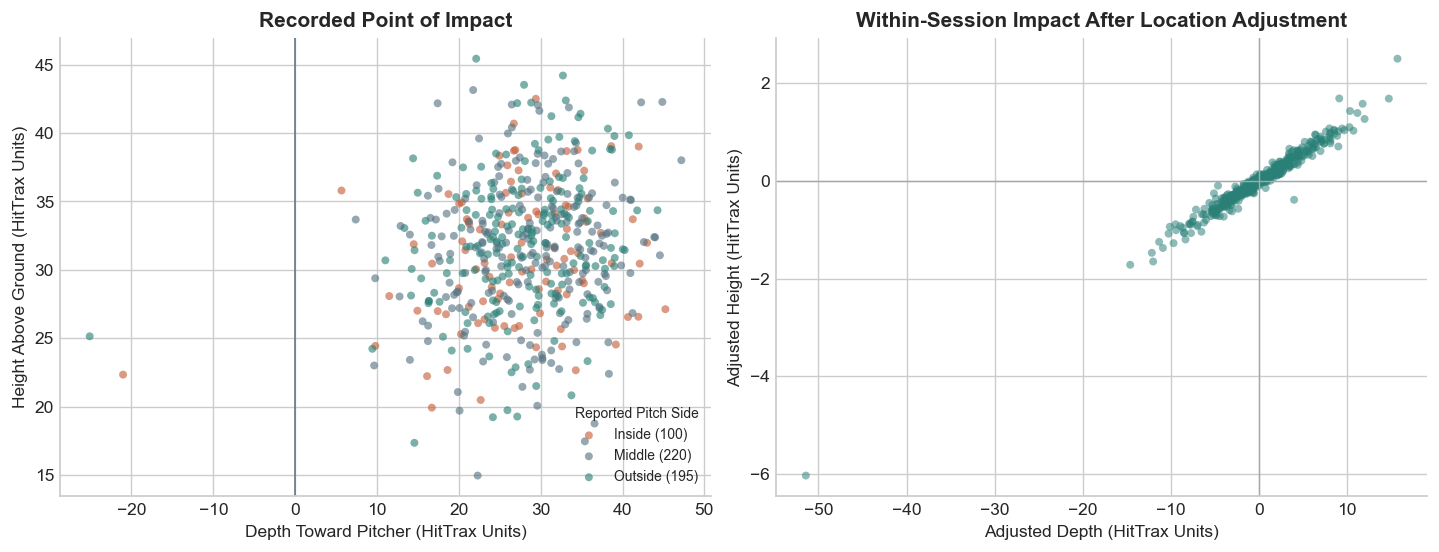

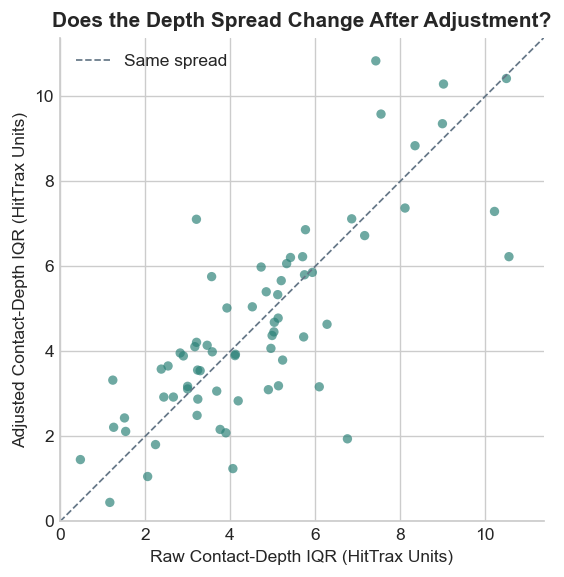

In [7]:
palette = {'Inside': '#c45d39', 'Middle': '#547281', 'Outside': '#2a8077', 'Unavailable': '#a0a5ad'}
zone = np.select([impact.inside_in.gt(SIDE_BAND_IN), impact.inside_in.lt(-SIDE_BAND_IN),
                  impact.inside_in.notna()], ['Inside', 'Outside', 'Middle'], default='Unavailable')
impact['pitch_band'] = zone

fig, ax = plt.subplots(1, 2, figsize=(11.4, 4.3), constrained_layout=True)
for band, color in palette.items():
    dots = impact.loc[impact.pitch_band.eq(band)]
    if not dots.empty:
        ax[0].scatter(dots.poi_z, dots.poi_y, label=f'{band} ({len(dots)})',
                      s=21, color=color, alpha=.62, edgecolor='none')
ax[0].set(title='Recorded Point of Impact', xlabel='Depth Toward Pitcher (HitTrax Units)',
          ylabel='Height Above Ground (HitTrax Units)')
ax[0].axvline(0, linewidth=.9, color='#607080')
ax[0].legend(frameon=False, loc='lower right', fontsize=8, title='Reported Pitch Side', title_fontsize=8)

if cluster_supported:
    for label, color in [('Deeper component', '#2a8077'), ('Forward component', '#c45d39')]:
        dots = paired.loc[paired.exploratory_cluster.eq(label)]
        ax[1].scatter(dots.poi_z_adjusted, dots.poi_y_adjusted, s=21, alpha=.55,
                      label=label, color=color, edgecolor='none')
    ax[1].legend(frameon=False, fontsize=8)
else:
    ax[1].scatter(paired.poi_z_adjusted, paired.poi_y_adjusted, s=21, alpha=.53,
                  color='#2a8077', edgecolor='none')
ax[1].axvline(0, linewidth=.8, color='#a1a9af')
ax[1].axhline(0, linewidth=.8, color='#a1a9af')
ax[1].set(title='Within-Session Impact After Location Adjustment',
          xlabel='Adjusted Depth (HitTrax Units)', ylabel='Adjusted Height (HitTrax Units)')
fig.savefig(FIG / 'contact_location_map.png', dpi=165, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(6.7, 4.5), constrained_layout=True)
ax.scatter(matched_summary.paired_raw_depth_iqr, matched_summary.paired_adjusted_depth_iqr,
           s=29, color='#2a8077', alpha=.68, edgecolor='none')
limit = 1.05 * matched_summary[['paired_raw_depth_iqr', 'paired_adjusted_depth_iqr']].max().max()
ax.plot([0, limit], [0, limit], color='#657787', linestyle='--', linewidth=1, label='Same spread')
ax.set(xlim=(0, limit), ylim=(0, limit), title='Does the Depth Spread Change After Adjustment?',
       xlabel='Raw Contact-Depth IQR (HitTrax Units)',
       ylabel='Adjusted Contact-Depth IQR (HitTrax Units)')
ax.set_aspect('equal', adjustable='box')
ax.legend(frameon=False)
fig.savefig(FIG / 'depth_spread_comparison.png', dpi=165, bbox_inches='tight')
plt.show()

,session_swing,label,inside_in,vertical_distance,poi_z,poi_y,hand_depth_cm,hand_relative_cm
0,492_5,Deeper contact,0.0,-10.4,20.09,19.72,2.60,33.61
1,492_4,Farther forward,0.7,-9.7,38.34,22.41,26.04,45.32


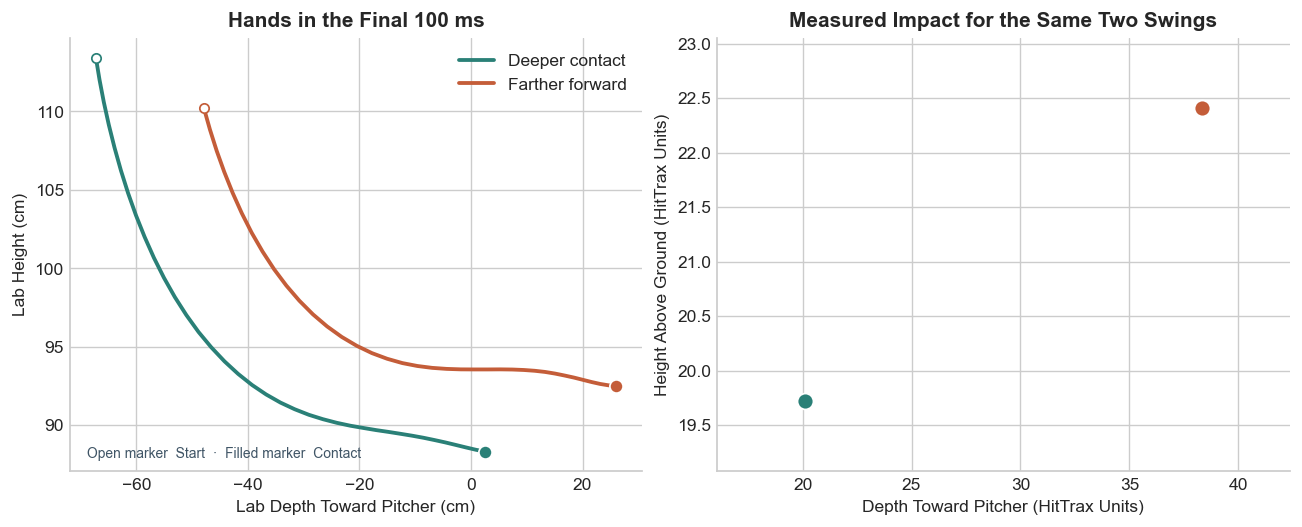

In [8]:
def select_pair(frame):
    best = None
    best_score = None
    min_depth, max_depth = frame.poi_z.quantile(list(PAIR_DEPTH_QUANTILES))
    for _, group in frame.groupby(PROFILE, sort=True):
        low, high = group.poi_z.quantile([.25, .75])
        eligible = group.loc[group[KEY].isin(traces) & group.poi_z.between(min_depth, max_depth)
                             & group.inside_in.abs().le(8.5)].sort_values(KEY)
        for deep in eligible.loc[eligible.poi_z.le(low)].itertuples(index=False):
            for front in eligible.loc[eligible.poi_z.ge(high)].itertuples(index=False):
                depth_gap = front.poi_z - deep.poi_z
                pitch_gap = np.hypot(front.inside_in - deep.inside_in,
                                     front.vertical_distance - deep.vertical_distance)
                score = (depth_gap, -pitch_gap)
                if depth_gap > 0 and pitch_gap <= PAIR_MAX_PITCH_GAP_IN and (
                        best_score is None or score > best_score):
                    best = (deep.session_swing, front.session_swing)
                    best_score = score
    return best


selected = select_pair(paired)
pair_table = pd.DataFrame()
if selected is None:
    print('No pair met the pitch-location and complete hand-trace criteria.')
else:
    pair_table = paired.set_index(KEY).loc[list(selected)].reset_index()
    pair_table['label'] = ['Deeper contact', 'Farther forward']
    plot_columns = [KEY, 'label', 'inside_in', 'vertical_distance',
                    'poi_z', 'poi_y', 'hand_depth_cm', 'hand_relative_cm']
    display(pair_table[plot_columns].round(2))

    fig, axes = plt.subplots(1, 2, figsize=(10.3, 4.1), constrained_layout=True)
    for row, color in zip(pair_table.itertuples(index=False), ['#2a8077', '#c45d39']):
        trace = traces[row.session_swing]
        axes[0].plot(trace[:, 0], trace[:, 1], color=color, linewidth=2.2, label=row.label)
        axes[0].scatter(trace[0, 0], trace[0, 1], s=29, facecolor='white', edgecolor=color, zorder=4)
        axes[0].scatter(trace[-1, 0], trace[-1, 1], s=58, color=color, edgecolor='white', zorder=5)
        axes[1].scatter(row.poi_z, row.poi_y, s=84, color=color, edgecolor='white', zorder=4)
    axes[0].set(title='Hands in the Final 100 ms', xlabel='Lab Depth Toward Pitcher (cm)',
                ylabel='Lab Height (cm)')
    axes[0].text(.03, .03, 'Open marker  Start  ·  Filled marker  Contact',
                 transform=axes[0].transAxes, fontsize=8, color='#405566')
    axes[0].legend(frameon=False)
    axes[1].set(title='Measured Impact for the Same Two Swings',
                xlabel='Depth Toward Pitcher (HitTrax Units)',
                ylabel='Height Above Ground (HitTrax Units)')
    axes[1].margins(x=.22, y=.24)
    fig.savefig(FIG / 'matched_swing_overlay.png', dpi=165, bbox_inches='tight')
    plt.show()

In [9]:
exports = {
    'swing_audit': data.drop(columns='hittrax_join'),
    'session_profiles': profiles.reset_index(),
    'matched_swings': paired,
    'event_sensitivity': event_sensitivity,
    'pitch_location_diagnostic': coupling.reset_index(names='reported_pitch_field'),
    'hand_depth_associations': slopes,
    'cluster_fold_scores': fold_scores,
}
if not pair_table.empty:
    exports['matched_swing_example'] = pair_table[plot_columns]
else:
    (OUT / 'matched_swing_example.csv').unlink(missing_ok=True)
    (FIG / 'matched_swing_overlay.png').unlink(missing_ok=True)

for name, table in exports.items():
    table.to_csv(OUT / f'{name}.csv', index=False)

manifest = {
    'source': 'OpenBiomechanics Dataset v1',
    'input_sha256': {path.name: file_hash(path) for path in
                     [RAW / 'metadata.csv', RAW / 'hittrax.csv', landmark_path]},
    'counts': {'metadata_swings': len(data), 'hittrax_rows': len(hittrax),
               'zero_impact_triples': int(zero_triple.sum()), 'valid_impact_swings': len(impact),
               'matched_location_swings': len(paired), 'matched_profiles': len(matched_summary)},
    'unmatched_hittrax_ids': unmatched_hittrax,
    'unmatched_landmark_ids': unmatched_landmarks,
    'settings': {'seed': SEED, 'minimum_swings': MIN_SWINGS, 'grouped_folds': len(folds),
                 'maximum_landmark_gap_seconds': MAX_SAMPLE_GAP_S,
                 'impact_units': 'HitTrax source units', 'pitch_band_cut_in': SIDE_BAND_IN,
                 'max_pair_pitch_distance_in': PAIR_MAX_PITCH_GAP_IN,
                 'pair_depth_quantiles': PAIR_DEPTH_QUANTILES,
                 'slope_bootstraps': BOOTSTRAPS, 'cluster_bootstraps': CLUSTER_BOOTSTRAPS},
    'cluster_screen': cluster_screen
}
(OUT / 'run_manifest.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')
assert len(data) == len(metadata) and not data[KEY].duplicated().any()
assert not paired[IMPACT].eq(0).all(axis=1).any()
assert (paired.groupby('user').location_fold.nunique() == 1).all()

raw = matched_summary.paired_raw_depth_iqr.median()
adjusted = matched_summary.paired_adjusted_depth_iqr.median()
print(f'Median profile depth IQR on the matched swings: {raw:.2f} raw and {adjusted:.2f} '
      'after conditioning on reported pitch location, in HitTrax units.')
for row in slopes.loc[slopes.comparison.eq('Location adjusted')].itertuples(index=False):
    print(f'{row.hand_reference}-referenced hand depth: {row.change_cm_per_10_poi_units:+.2f} cm '
          f'per 10 HitTrax units forward (95% conditional interval '
          f'{row.lo_95_cm:+.2f} to {row.hi_95_cm:+.2f} cm).')
if cluster_supported:
    print('Two components passed the exploratory screen. Their interpretation needs independent data.')
else:
    print('The two-component fit fell short of the exploratory screen. Use the continuous contact map.')
if abs(coupling.loc['inside_in', 'poi_x_toward_batter']) >= .90 or abs(
        coupling.loc['vertical_distance', 'poi_y']) >= .90:
    print('Reported pitch location closely tracks the corresponding impact coordinates. '
          'Treat the location-adjusted numbers as conditional descriptions of these exported fields.')
print('Results: results/contact_point_stability/')
print('Figures: figures/contact_point_stability/')

Median profile depth IQR on the matched swings: 4.36 raw and 4.09 after conditioning on reported pitch location, in HitTrax units.
Lab-referenced hand depth: +9.44 cm per 10 HitTrax units forward (95% conditional interval +6.76 to +13.02 cm).
Pelvis-referenced hand depth: +3.75 cm per 10 HitTrax units forward (95% conditional interval +2.66 to +5.27 cm).
The two-component fit fell short of the exploratory screen. Use the continuous contact map.
Reported pitch location closely tracks the corresponding impact coordinates. Treat the location-adjusted numbers as conditional descriptions of these exported fields.
Results: results/contact_point_stability/
Figures: figures/contact_point_stability/
